# Predict the flight of a D12 rocket

**Engr 101 guided project · Rocket 1 · working draft**

How high will our rocket fly, when will it reach that height, and what evidence makes that prediction credible?
Build a one-dimensional model using a measured motor thrust curve, a straight-average wind-tunnel drag
coefficient, and Newton's second law. Use the prediction to plan instrumentation and compare it with a later flight.

Complete the **five code exercises**, the checks, and the short written explanations. Supplied code handles
file loading, plotting, and event bookkeeping. Your code supplies the impulse estimate, measured Cd,
signed drag, force balance, and numerical motion update.

Work through the sections in order across the modeling lessons. Save a personal or team copy before editing.
`Shift+Enter` runs a cell. A deliberate `NotImplementedError` marks a code exercise you must complete.
Finish by restarting the kernel and running all cells from the top; this catches hidden state from earlier runs.

This project models the first flight's **fixed-delay recovery parachute**. The later altitude-triggered deployment
mechanism is a separate design task. The example configuration is not the measured flight article or launch approval.


## Project record

Team and members: **enter here**

Date and configuration identifier: **enter here**

Sources and assistance used: **enter here**

Final evidence: this completed notebook; acceleration, velocity, and altitude figures; a table of predictions;
time-step and sensitivity checks; a brief explanation of assumptions and limitations; a saved preflight configuration.
The instructor will specify collaboration and documentation rules. This computer-based project is separate from
the supervised paper-and-calculator assessments.


In [5]:
from pathlib import Path
from dataclasses import asdict, replace
from datetime import datetime, timezone
import json
import hashlib
import shutil
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in this folder, instructor/, or the repository root.
candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'projects' / 'rocket_prediction']
PROJECT = next((p for p in candidates if (p / 'flight_support.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open this notebook from the repository or project folder.')
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from flight_support import FlightInputs, load_motor, simulate, summary
OUTPUT = PROJECT / 'outputs'
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True})
print('Project:', PROJECT.name, '| Python:', sys.version.split()[0], '| NumPy:', np.__version__)


Project: rocket_prediction | Python: 3.12.16 | NumPy: 2.5.5


## 1  Define the configuration and coordinate system

Up is positive. Height $h=0$ is the launch point, so height is **above the launch reference**, not sea level.
Use SI units throughout. Mass includes the motor, battery, instrument, parachute, and structure.

The course baseline is about 600 mm long, uses a **D12**, and has a desired maximum altitude of 100 m.
Length alone does not determine mass or drag. The values below are **demonstration assumptions**; replace
them with instructor-provided or measured inputs and document each source before making a flight prediction.
The 3 s delay is an example recovery delay to confirm against the actual motor variant.

We hold mass and density constant, neglect wind and tilt, model drag using one mean Cd, and represent
parachute opening as an instantaneous change in Cd and area. A constant representative mass is an approximation
to the changing propellant mass. Explain its expected effect rather than calling it exact.


In [6]:
configuration_label = 'DEMONSTRATION — replace with measured/instructor inputs'
input_sources = {
    'mass': 'demonstration assumption, not weighed hardware',
    'diameter': 'legacy nominal example, confirm actual vehicle',
    'density': 'demonstration instructor input; no atmosphere calculator',
    'recovery': 'demonstration parachute and delay, confirm actual configuration',
}
mass_kg = 0.40
body_diameter_m = 0.0574
body_area_m2 = np.pi * body_diameter_m**2 / 4
density_kg_m3 = 0.95
parachute_diameter_m = 0.6096
parachute_area_m2 = np.pi * parachute_diameter_m**2 / 4
parachute_cd = 1.75
ejection_delay_s = 3.0
g = 9.81  # positive magnitude; weight force will be negative
altitude_target_m = 100.0
print(configuration_label)
print(f'Body frontal area: {body_area_m2:.6f} m²')


DEMONSTRATION — replace with measured/instructor inputs
Body frontal area: 0.002588 m²


**Explain:** Draw a force diagram just after liftoff and another during descent under the parachute.
Label directions. Which assumptions are likely useful for a first prediction? Which might limit its accuracy?

**Your response:**


## 2  Inspect the D12 thrust curve and make an estimate

The supplied CSV is exported from Engr 201's `EstesD12.mat`; provenance is in `data/README.md`.
It is a representative thrust curve, not a measurement of your individual motor. The model linearly interpolates
between samples and averages the endpoint thrusts within a time interval.

The area under the thrust curve is total impulse, $J=\int T\,dt$, in N·s. For a quick no-drag estimate,
assume the motor's average thrust acts from launch for its full burn time:

$$v_b\approx\frac{J-mgt_b}{m},\qquad h_b\approx\frac12v_bt_b,
\qquad h_{peak}\approx h_b+\frac{v_b^2}{2g}.$$

This estimate ignores the real timing of thrust and the pad constraint. It is a plausibility check, not a rigorous
upper bound. The coast-height term starts at burnout; do not forget the height gained during the burn.


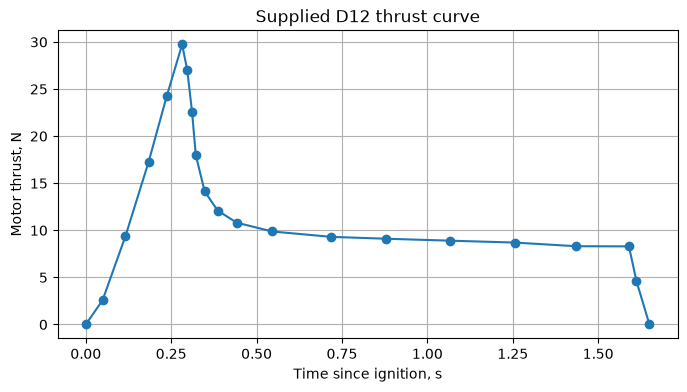

Burn time: 1.650 s | Impulse: 16.839 N·s


In [7]:
motor_time_s, motor_thrust_N = load_motor(PROJECT / 'data' / 'estes_d12.csv')
burn_time_s = float(motor_time_s[-1])
impulse_N_s = np.trapezoid(motor_thrust_N, motor_time_s)
fig, ax = plt.subplots()
ax.plot(motor_time_s, motor_thrust_N, 'o-')
ax.set(xlabel='Time since ignition, s', ylabel='Motor thrust, N', title='Supplied D12 thrust curve')
plt.show()
print(f'Burn time: {burn_time_s:.3f} s | Impulse: {impulse_N_s:.3f} N·s')


In [8]:
# Exercise 1: calculate burnout speed and peak altitude using the estimate above.
# Replace the raise statement with your calculations and print your result.
raise NotImplementedError('Exercise 1: calculate burnout_speed_estimate_m_s and peak_estimate_m')


NotImplementedError: Exercise 1: calculate burnout_speed_estimate_m_s and peak_estimate_m

**Check:** N·s divided by kg has units of m/s. What physical effect does the subtracted `mass_kg * g * burn_time_s`
represent? Why should you expect this simple estimate to differ from the numerical model?

**Your response:**


## 3  Use a straight-average wind-tunnel Cd

For a measured drag-force **magnitude** $D$ at speed $V>0$:

$$\rho=\frac{P}{RT},\qquad C_D=\frac{2D}{\rho V^2 A},\qquad
\overline{C_D}=\frac{1}{n}\sum_{i=1}^n C_{D,i}.$$

Convert pressure from kPa to Pa and temperature from °C to K. Use $R=287.058$ J/(kg·K).
Calculate Cd for each designated valid row, then take its **straight arithmetic average**. Do not curve fit,
and do not substitute average force and speed into the equation instead of averaging the individual Cd values.

The included legacy tunnel data are **practice data**, not measurements of your new rocket. The practice reference
diameter below is a declared teaching assumption, not verified tunnel-model metadata. Use your actual reference area
and new measurements for the flight prediction. Preserve original data and justify any exclusions by instrument or
test criteria established with the instructor, not by whether a point improves the answer.


In [ ]:
tunnel_file = PROJECT / 'data' / 'wind_tunnel_practice.csv'
tunnel_reference_diameter_m = 0.0574  # practice assumption; replace with tested model dimensions
tunnel_area_m2 = np.pi * tunnel_reference_diameter_m**2 / 4
tunnel = np.genfromtxt(tunnel_file, delimiter=',', names=True)
P_Pa = tunnel['pressure_kPa'] * 1000
T_K = tunnel['temperature_C'] + 273.15
V_m_s = tunnel['speed_m_s']
D_N = tunnel['drag_N']
assert np.all(V_m_s > 0), 'Zero-speed data cannot be used to calculate Cd.'
assert np.all(D_N > 0), 'Confirm force direction and tare before using drag magnitudes.'


In [ ]:
# Exercise 2: arrays support element-by-element arithmetic in NumPy.
# Define rho_tunnel_kg_m3, cd_each, and cd_mean. Hint: np.mean(array).
raise NotImplementedError('Exercise 2: calculate each Cd and its straight average')


In [ ]:
assert np.all(np.isfinite(cd_each)) and np.all(cd_each > 0)
assert np.isclose(cd_mean, np.sum(cd_each) / len(cd_each)), 'Use a straight arithmetic average.'
fig, ax = plt.subplots()
ax.plot(V_m_s, cd_each, 'o', label='Individual practice measurements')
ax.axhline(cd_mean, color='tab:orange', label=f'Straight mean = {cd_mean:.3f}')
ax.set(xlabel='Tunnel speed, m/s', ylabel='Drag coefficient, dimensionless')
ax.legend()
plt.show()
print(f'Mean Cd: {cd_mean:.4f} | Range: {np.min(cd_each):.4f} to {np.max(cd_each):.4f}')


**Explain:** What information is lost when the measured values are replaced by one mean? What might explain
their variation? State which data and reference area your prediction uses and whether they describe your actual rocket.

**Your response:**


## 4  Build the signed force balance

With upward positive, weight is $-mg$ and thrust is positive. In still air, signed drag is

$$F_D=-\frac12\rho C_D A\,v|v|.$$

Unlike $-\tfrac12\rho C_D A v^2$, this expression changes sign during descent.
The **net force is the signed sum**, not the largest individual force:

$$\sum F=T+F_D-mg,\qquad a=\frac{\sum F}{m}.$$

Example: for $T=8.0$ N, $F_D=-1.0$ N, $mg=4.9$ N, and $m=0.50$ kg,
the net force is +2.1 N and acceleration is +4.2 m/s². Use your calculator to confirm this before coding.


In [ ]:
def drag_force(density, velocity, cd, area):
    # Exercise 3: return signed drag in newtons. abs(velocity) gives |v|.
    raise NotImplementedError('Exercise 3: signed drag')


In [ ]:
assert np.isclose(drag_force(1.0, 10.0, 0.5, 0.01), -0.25), 'Upward motion needs downward drag.'
assert np.isclose(drag_force(1.0, -10.0, 0.5, 0.01), 0.25), 'Downward motion needs upward drag.'
assert drag_force(1.0, 0.0, 0.5, 0.01) == 0
print('Drag direction and magnitude checks passed.')


In [ ]:
def acceleration(thrust, signed_drag, mass, gravity):
    # Exercise 4: gravity is a positive magnitude; signed_drag already has its sign.
    raise NotImplementedError('Exercise 4: sum the forces and divide by mass')


In [ ]:
assert np.isclose(acceleration(8.0, -1.0, 0.5, 9.8), 4.2)
assert np.isclose(acceleration(0.0, 0.0, 0.5, g), -g), 'Free flight without thrust or drag is free fall.'
assert np.isclose(acceleration(0.5 * g, 0.0, 0.5, g), 0.0)
print('Force-balance checks passed.')


## 5  Advance motion one small time step

Use the acceleration calculated for this interval to update velocity, then use the **new** velocity for height:

$$a_n=\frac{T_{avg,n}+F_D(v_n)-mg}{m},\qquad
v_{n+1}=v_n+a_n\Delta t,\qquad
h_{n+1}=h_n+v_{n+1}\Delta t.$$

This is a first-order, semi-implicit Euler update. It differs from explicit Euler, which uses the old velocity
in the height update. Both approximate continuous motion; smaller steps help you evaluate the error.
Use one convention consistently and explain it.

Worked check: with h=10 m, v=2 m/s, a=−9.8 m/s², and dt=0.1 s,
the new velocity is 1.02 m/s and this update gives a new height of 10.102 m.


In [ ]:
def advance_step(height, velocity, thrust, signed_drag, mass, gravity, dt):
    # Exercise 5: calculate acceleration, new_velocity, and new_height.
    # Return them in this order: new_height, new_velocity, acceleration.
    raise NotImplementedError('Exercise 5: one numerical time step')


In [ ]:
assert np.allclose(advance_step(10, 2, 0, 0, 0.5, 9.8, 0.1), (10.102, 1.02, -9.8))
assert np.allclose(advance_step(10, 2, 4.9, 0, 0.5, 9.8, 0.1), (10.2, 2, 0))
print('One-step checks passed. Explain why these are useful before simulating a complete flight.')


## 6  Run the complete flight prediction

The provided `simulate` loop calls your drag and step functions repeatedly. Open `flight_support.py` to trace it.
It holds the rocket on the pad until the predicted motion is upward, uses body drag through powered flight and
coast, switches to parachute drag after burnout plus the recovery delay, and stops at ground contact.
It splits steps at thrust-curve knots and the deployment event, so averaging a piecewise-linear thrust curve
does not skip an event. It interpolates touchdown within the final interval. It rejects runs that never lift off
or do not return before a maximum run time.

Acceleration is the net inertial acceleration, including gravity. An accelerometer does not directly report this
same quantity. At the pad the constraint makes this model's acceleration zero; stored acceleration samples after
that represent the preceding integration interval. Do not interpret a plotted instantaneous canopy-opening jump
as a prediction of structural opening loads.


In [ ]:
inputs = FlightInputs(
    mass_kg=mass_kg, density_kg_m3=density_kg_m3, body_cd=cd_mean,
    body_area_m2=body_area_m2, parachute_cd=parachute_cd,
    parachute_area_m2=parachute_area_m2, ejection_delay_s=ejection_delay_s,
)
dt_s = 0.02
flight = simulate(inputs, motor_time_s, motor_thrust_N, drag_force, advance_step, dt_s=dt_s)
predictions = summary(flight)
print(configuration_label)
for name, value in predictions.items():
    print(f'{name}: {value:.3f}')
if flight['deployment_s'] > flight['time_s'][-1]:
    print('Recovery deployment occurs after predicted touchdown: review the configuration.')
print('Desired maximum altitude:', altitude_target_m, 'm; this calculation is not launch authorization.')


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True, constrained_layout=True)
for ax, key, label in zip(axes,
        ['acceleration_m_s2', 'velocity_m_s', 'altitude_m'],
        ['Acceleration, m/s²', 'Vertical velocity, m/s', 'Height above launch, m']):
    ax.plot(flight['time_s'], flight[key], label='D12 prediction')
    ax.axvline(flight['burnout_s'], color='0.4', linestyle=':', label='Burnout')
    if flight['deployment_s'] <= flight['time_s'][-1]:
        ax.axvline(flight['deployment_s'], color='tab:orange', linestyle='--', label='Recovery deployment')
    ax.set_ylabel(label)
axes[-1].axhline(altitude_target_m, color='tab:red', linestyle='--', label='100 m planning target')
axes[-1].set_xlabel('Time since ignition, s')
axes[-1].legend(loc='best')
fig.suptitle(configuration_label)
fig.savefig(OUTPUT / 'flight_prediction.svg')
fig.savefig(OUTPUT / 'flight_prediction.png', dpi=140)
plt.show()


**Explain:** Identify powered flight, coast, apogee, and parachute descent. Can recovery deployment occur before
or after apogee with a fixed motor delay? Compare your peak height with the rough estimate and the 100 m target.
If the target is exceeded, identify what evidence or design review is needed next; do not adjust measured inputs
to force agreement. What would change if the launch configuration became heavier?

**Your response:**


## 7  Check numerical error and sensitivity

A plot that looks smooth can still be wrong. First keep the physical inputs fixed and halve the time step.
Then keep the numerical method fixed and vary an uncertain physical input. These answer different questions.
Choose and justify an acceptable change in apogee for the decision you are making.


In [ ]:
step_sizes_s = [0.04, 0.02, 0.01, 0.005]
step_results = []
for step_size in step_sizes_s:
    trial = simulate(inputs, motor_time_s, motor_thrust_N, drag_force, advance_step, dt_s=step_size)
    result = summary(trial)
    step_results.append(result['apogee_m'])
    print(f'dt={step_size:.3f} s: apogee={result["apogee_m"]:.3f} m, flight={result["flight_time_s"]:.3f} s')
print(f'Apogee change on final halving: {abs(step_results[-1] - step_results[-2]):.4f} m')


In [ ]:
# This ±10% range is a teaching sensitivity study, not a measured uncertainty interval.
for factor in [0.9, 1.0, 1.1]:
    trial_inputs = replace(inputs, mass_kg=inputs.mass_kg * factor)
    trial = simulate(trial_inputs, motor_time_s, motor_thrust_N, drag_force, advance_step, dt_s=0.01)
    print(f'Mass {trial_inputs.mass_kg:.3f} kg -> apogee {summary(trial)["apogee_m"]:.2f} m')


**Explain:** What time step will you use, and why? What does the mass study tell you? Repeat the study for Cd
or density. Distinguish a plausible input range from a measured confidence interval. Which uncertainty would be
most useful to reduce before launch?

**Your response:**


## 8  Preserve the preflight prediction

Change `configuration_label` and `input_sources` to describe the actual evidence before recording a flight prediction.
Preserve the original preflight notebook and export; do not overwrite them with a post-flight rerun. The next cell
creates a timestamped record containing inputs, data references, time step, predicted quantities, and trajectory.
The first export should still be labeled a demonstration until its inputs have been verified.


In [ ]:
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
run_folder = OUTPUT / f'prediction_{stamp}'
run_folder.mkdir()
record = {
    'configuration': configuration_label, 'created_utc': stamp,
    'inputs': asdict(inputs), 'input_sources': input_sources,
    'motor': 'data/estes_d12.csv', 'motor_label': 'D12',
    'tunnel_data': str(tunnel_file.name), 'tunnel_reference_area_m2': tunnel_area_m2,
    'dt_s': dt_s, 'method': 'semi-implicit Euler with event-aligned steps',
    'predictions': predictions,
}
record['data_sha256'] = {}
for source in [PROJECT / 'data' / 'estes_d12.csv', tunnel_file]:
    record['data_sha256'][source.name] = hashlib.sha256(source.read_bytes()).hexdigest()
    shutil.copyfile(source, run_folder / source.name)
(run_folder / 'prediction.json').write_text(json.dumps(record, indent=2), encoding='utf-8')
np.savetxt(run_folder / 'trajectory.csv',
           np.column_stack([flight[k] for k in ['time_s', 'acceleration_m_s2', 'velocity_m_s', 'altitude_m']]),
           delimiter=',', header='time_s,acceleration_m_s2,velocity_m_s,altitude_m', comments='')
print('Saved:', run_folder.name)


## 9  Prepare the prediction argument and later flight comparison

Use the following headings for a concise report contribution; refer to notebook figures and the prediction table.

- **Model and assumptions:** coordinate reference, forces, numerical update, recovery timing, limitations.
- **Inputs and provenance:** measured versus supplied versus assumed quantities; reference area and mean Cd.
- **Predictions and checks:** peak height, time to peak, upward speed, flight duration, numerical convergence.
- **Implications:** instrument range and sampling needs, comparison with the 100 m target, and remaining questions.

After flight, keep the original prediction. Create a separately named rerun with measured mass and flight-day
environmental inputs. Align time origins and subtract the measured launch reference from altitude data before
overlaying them. Compare quantities and trajectories; investigate model, input, and measurement limitations.
A small residual does not by itself prove the model is valid, and matching only apogee can hide timing errors.

**Your prediction argument:**

**Later flight comparison plan:**

## Submission check

- All five code exercises are complete and their checks pass.
- The kernel restarts and all cells execute in order.
- Inputs are labeled and sourced; demonstration values are not presented as measured hardware.
- Figures have units, clear references, and captions/explanations suitable for the report.
- Time-step and physical-input studies are interpreted, not just printed.
- The original preflight prediction is preserved separately from any later rerun.
- Sources and assistance are documented according to the instructor's directions.

Adapted from Engr 201's rocket-prediction project and algorithm, local reviewed revision
`b307a9e96fa7d3dbdfb82caf2f1197efcedc867d`. See the project README and data provenance for the exact sources.
